In [1]:
import pandas as pd
import numpy as np

# Original data from the data folder (this table stays unchanged)
acc_df = pd.read_csv("data/accidents_2025_with_population.csv",
                     dtype={"accident_id": str}, low_memory=False)

print(f"Shape: {acc_df.shape[0]:,} rows × {acc_df.shape[1]} columns")
acc_df.head()

Shape: 272,812 rows × 41 columns


,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,single_type,vulnerable_vs_vehicle,date,date_check,killed,ags,population,area_km2,population_per_km2,city_note
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,Friday,Accident with slightly injured,...,1,0,2025-05-09,ok,0,1060007,1067.0,34.85,31.0,ok
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,Saturday,Accident with slightly injured,...,1,0,2025-04-05,ok,0,1062053,9052.0,11.36,797.0,ok
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,Saturday,Accident with slightly injured,...,1,0,2025-01-18,ok,0,1056015,51375.0,21.36,2405.0,ok
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,Wednesday,Accident with slightly injured,...,0,1,2025-03-26,ok,0,1055028,10842.0,69.07,157.0,ok
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,Tuesday,Accident with slightly injured,...,1,0,2025-02-25,ok,0,1058116,834.0,13.89,60.0,ok


In [2]:
acc_df.columns

Index(['accident_id', 'state', 'region', 'district', 'municipality', 'year',
       'month', 'hour', 'weekday', 'severity', 'accident_kind',
       'accident_type', 'light', 'road_condition', 'bicycle', 'car',
       'pedestrian', 'motorcycle', 'truck', 'other_vehicle', 'utm_x', 'utm_y',
       'longitude', 'latitude', 'location_check', 'severe', 'state_name',
       'year_month', 'participants', 'n_participant_types', 'vulnerable',
       'single_type', 'vulnerable_vs_vehicle', 'date', 'date_check', 'killed',
       'ags', 'population', 'area_km2', 'population_per_km2', 'city_note'],
      dtype='str')

In [3]:
TARGET = "severe"

# Not used
EXCLUDED_COLS = {
    "leakage":        ["severity", "killed"],
    "post_accident":  ["accident_kind", "accident_type"],          # Szenario C
    "id_constant":    ["accident_id", "ags", "year", "year_month", "date",
                       "date_check", "location_check", "city_note"],
    "duplicate":      ["state", "utm_x", "utm_y", "participants", "single_type",
                       "population", "area_km2"],
    "high_cardinality": ["region", "district", "municipality"],   # possibly later: target encoding
}

# Szenario C features
CATEGORICAL_C = ["state_name", "light", "road_condition"]
BINARY_C      = ["bicycle", "car", "pedestrian", "motorcycle", "truck", "other_vehicle"]
DERIVED_C     = ["vulnerable", "vulnerable_vs_vehicle"]           # only for tree models
TIME_C        = ["month", "hour", "weekday"]                      # cyclical encoding comes in the next step
NUMERIC_C     = ["n_participant_types", "longitude", "latitude", "population_per_km2"]

# Check: is every column accounted for exactly once?
all_listed = ([TARGET] + sum(EXCLUDED_COLS.values(), [])
              + CATEGORICAL_C + BINARY_C + DERIVED_C + TIME_C + NUMERIC_C)
print("Not assigned:", sorted(set(acc_df.columns) - set(all_listed)))
print("Assigned twice:", sorted({c for c in all_listed if all_listed.count(c) > 1}))
print("Unknown:", sorted(set(all_listed) - set(acc_df.columns)))

Not assigned: []
Assigned twice: []
Unknown: []


In [4]:
import os
from sklearn.model_selection import train_test_split

# Model table: only the chosen columns (+ ID, target and accident kind/type for the comparison with Tiziano)
COMPARE_ONLY = ["accident_kind", "accident_type"]   # NOT a Szenario C feature, only for step 2 (sanity check)
acc_model_df = acc_df[["accident_id"] + CATEGORICAL_C + BINARY_C + DERIVED_C + TIME_C
                      + NUMERIC_C + COMPARE_ONLY + [TARGET]].copy()

# Time features as Tiziano did (cyclical + weekend)
acc_model_df["hour_sin"]   = np.sin(2 * np.pi * acc_model_df["hour"] / 24)
acc_model_df["hour_cos"]   = np.cos(2 * np.pi * acc_model_df["hour"] / 24)
acc_model_df["month_sin"]  = np.sin(2 * np.pi * acc_model_df["month"] / 12)
acc_model_df["month_cos"]  = np.cos(2 * np.pi * acc_model_df["month"] / 12)
acc_model_df["is_weekend"] = acc_model_df["weekday"].isin(["Saturday", "Sunday"]).astype(int)

# Population density is very skewed -> log scale
acc_model_df["log_pop_density"] = np.log1p(acc_model_df["population_per_km2"])

TIME_FEATURES_C = ["hour_sin", "hour_cos", "month_sin", "month_cos", "is_weekend"]

# Split 70/15/15, stratified by target (Tiziano's split files are used if they exist in data/splits)
split_dir = "data/splits"
if os.path.exists(f"{split_dir}/train.csv.gz"):
    split_ids = {name: set(pd.read_csv(f"{split_dir}/{name}.csv.gz", usecols=["UIDENTSTLAE"],
                                       dtype={"UIDENTSTLAE": str})["UIDENTSTLAE"])
                 for name in ["train", "val", "test"]}
    acc_model_df["split"] = np.select(
        [acc_model_df["accident_id"].isin(split_ids[n]) for n in ["train", "val", "test"]],
        ["train", "val", "test"], default="missing")
    print("Using Tiziano's splits")
else:
    ids_train, ids_rest = train_test_split(acc_model_df["accident_id"], test_size=0.30,
                                           stratify=acc_model_df[TARGET], random_state=42)
    rest_target = acc_model_df.set_index("accident_id").loc[ids_rest, TARGET]
    ids_val, ids_test = train_test_split(ids_rest, test_size=0.50,
                                         stratify=rest_target, random_state=42)
    acc_model_df["split"] = np.select(
        [acc_model_df["accident_id"].isin(ids_train), acc_model_df["accident_id"].isin(ids_val)],
        ["train", "val"], default="test")
    print("Own stratified split 70/15/15 (random_state=42)")

acc_train_df = acc_model_df[acc_model_df["split"] == "train"].copy()
acc_val_df   = acc_model_df[acc_model_df["split"] == "val"].copy()
acc_test_df  = acc_model_df[acc_model_df["split"] == "test"].copy()   # stays untouched until the final model

print(f"acc_model_df: {acc_model_df.shape[0]:,} rows × {acc_model_df.shape[1]} columns")
print(acc_model_df.groupby("split")[TARGET].agg(rows="size", share_severe="mean").round(4))

Using Tiziano's splits
acc_model_df: 272,812 rows × 29 columns
         rows  share_severe
split                      
test    40927        0.1571
train  190970        0.1571
val     40915        0.1569


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Feature sets for the comparison (steps 3-5)
FEATURE_SETS = {
    "Tiziano (with kind/type)": {
        "cat": CATEGORICAL_C + ["accident_kind", "accident_type"],
        "bin": BINARY_C + ["is_weekend"],
        "num": ["hour_sin", "hour_cos", "month_sin", "month_cos", "n_participant_types", "longitude", "latitude"],
    },
    "Szenario C": {
        "cat": CATEGORICAL_C,
        "bin": BINARY_C + ["is_weekend"],
        "num": ["hour_sin", "hour_cos", "month_sin", "month_cos", "n_participant_types", "longitude", "latitude"],
    },
    "Szenario C + population": {
        "cat": CATEGORICAL_C,
        "bin": BINARY_C + ["is_weekend"],
        "num": ["hour_sin", "hour_cos", "month_sin", "month_cos", "n_participant_types", "longitude", "latitude",
                "log_pop_density"],
    },
}


def make_preprocessor(feature_set):
    """One-hot for categories, scaling for numbers. Fitted later inside the pipeline on train only."""
    return ColumnTransformer([
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), feature_set["cat"]),
        ("bin", "passthrough", feature_set["bin"]),
        ("num", StandardScaler(), feature_set["num"]),
    ], verbose_feature_names_out=False)


for name, fs in FEATURE_SETS.items():
    n_cols = len(make_preprocessor(fs).fit(acc_train_df).get_feature_names_out())
    print(f"{name:26s} {len(fs['cat']) + len(fs['bin']) + len(fs['num']):2d} features -> {n_cols} columns after one-hot")

Tiziano (with kind/type)   19 features -> 48 columns after one-hot
Szenario C                 17 features -> 33 columns after one-hot
Szenario C + population    18 features -> 34 columns after one-hot


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)

y_train_c = acc_train_df[TARGET]
y_val_c = acc_val_df[TARGET]


def best_f1_threshold(y_true, p):
    """Threshold with the best F1 on train (same method as Tiziano)."""
    precision, recall, thresholds = precision_recall_curve(y_true, p)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return thresholds[np.argmax(f1[:-1])]


brier_constant_c = brier_score_loss(y_val_c, np.full(len(y_val_c), y_train_c.mean()))

logreg_models_c, logreg_rows_c = {}, []
for name, fs in FEATURE_SETS.items():
    features = fs["cat"] + fs["bin"] + fs["num"]
    model = make_pipeline(make_preprocessor(fs), LogisticRegression(max_iter=2000))
    model.fit(acc_train_df[features], y_train_c)          # scaler + model learn from train only
    logreg_models_c[name] = model

    p_train = model.predict_proba(acc_train_df[features])[:, 1]
    p_val = model.predict_proba(acc_val_df[features])[:, 1]
    threshold = best_f1_threshold(y_train_c, p_train)
    flags = p_val >= threshold

    logreg_rows_c.append(pd.Series({
        "Brier skill": 1 - brier_score_loss(y_val_c, p_val) / brier_constant_c,
        "ROC-AUC": roc_auc_score(y_val_c, p_val),
        "PR-AUC": average_precision_score(y_val_c, p_val),
        "threshold": threshold,
        "% flagged": flags.mean() * 100,
        "precision": precision_score(y_val_c, flags),
        "recall": recall_score(y_val_c, flags),
        "F1": f1_score(y_val_c, flags),
    }, name=name))

logreg_results_c = pd.DataFrame(logreg_rows_c)
print(f"Validation, base rate {y_val_c.mean():.3f}  |  Tiziano's notebook: ROC-AUC 0.667, PR-AUC 0.264, F1 0.34")
logreg_results_c.round(4)

Validation, base rate 0.157  |  Tiziano's notebook: ROC-AUC 0.667, PR-AUC 0.264, F1 0.34


,Brier skill,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Tiziano (with kind/type),0.0463,0.6666,0.2629,0.1629,39.3230,0.2384,0.5974,0.3408
Szenario C,0.0271,0.6290,0.2325,0.1504,44.6975,0.2142,0.6100,0.3171
Szenario C + population,0.0436,0.6604,0.2600,0.1540,41.5300,0.2288,0.6054,0.3320


In [7]:
import time
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier

# Trees: Szenario C + population + derived features (useful ready-made interactions for trees)
fs_trees_c = {
    "cat": FEATURE_SETS["Szenario C + population"]["cat"],
    "bin": FEATURE_SETS["Szenario C + population"]["bin"] + DERIVED_C,
    "num": FEATURE_SETS["Szenario C + population"]["num"],
}
features_trees_c = fs_trees_c["cat"] + fs_trees_c["bin"] + fs_trees_c["num"]

tree_models_c = {
    "Random forest": make_pipeline(make_preprocessor(fs_trees_c), RandomForestClassifier(
        n_estimators=300, min_samples_leaf=50, max_features="sqrt", n_jobs=-1, random_state=42)),
    "Gradient boosting": make_pipeline(make_preprocessor(fs_trees_c), HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=500, max_leaf_nodes=31, min_samples_leaf=100,
        early_stopping=True, validation_fraction=0.1, random_state=42)),
}

tree_rows_c = []
for name, model in tree_models_c.items():
    start = time.time()
    model.fit(acc_train_df[features_trees_c], y_train_c)
    p_train = model.predict_proba(acc_train_df[features_trees_c])[:, 1]
    p_val = model.predict_proba(acc_val_df[features_trees_c])[:, 1]
    threshold = best_f1_threshold(y_train_c, p_train)
    flags = p_val >= threshold
    tree_rows_c.append(pd.Series({
        "Brier skill": 1 - brier_score_loss(y_val_c, p_val) / brier_constant_c,
        "ROC-AUC": roc_auc_score(y_val_c, p_val),
        "PR-AUC": average_precision_score(y_val_c, p_val),
        "threshold": threshold,
        "% flagged": flags.mean() * 100,
        "precision": precision_score(y_val_c, flags),
        "recall": recall_score(y_val_c, flags),
        "F1": f1_score(y_val_c, flags),
    }, name=f"Szenario C + population: {name}"))
    print(f"{name}: trained in {time.time() - start:.0f} s")

# Comparison with the logistic regressions (new table, old ones stay unchanged)
comparison_c = pd.concat([logreg_results_c, pd.DataFrame(tree_rows_c)])
comparison_c.round(4)

Random forest: trained in 7 s
Gradient boosting: trained in 2 s


,Brier skill,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Tiziano (with kind/type),0.0463,0.6666,0.2629,0.1629,39.3230,0.2384,0.5974,0.3408
Szenario C,0.0271,0.6290,0.2325,0.1504,44.6975,0.2142,0.6100,0.3171
Szenario C + population,0.0436,0.6604,0.2600,0.1540,41.5300,0.2288,0.6054,0.3320
Szenario C + population: Random forest,0.0496,0.6683,0.2716,0.1882,29.7030,0.2550,0.4826,0.3337
Szenario C + population: Gradient boosting,0.0504,0.6697,0.2713,0.1745,34.6645,0.2492,0.5505,0.3431


In [8]:
from sklearn.inspection import permutation_importance

gb_model_c = tree_models_c["Gradient boosting"]

# How much does PR-AUC on val drop when a feature is shuffled?
perm_c = permutation_importance(gb_model_c, acc_val_df[features_trees_c], y_val_c,
                                scoring="average_precision", n_repeats=5, random_state=42, n_jobs=-1)

importance_gb_c = (pd.DataFrame({"feature": features_trees_c,
                                 "PR-AUC drop": perm_c.importances_mean,
                                 "std": perm_c.importances_std})
                   .sort_values("PR-AUC drop", ascending=False)
                   .reset_index(drop=True))
importance_gb_c.round(4)

,feature,PR-AUC drop,std
0,log_pop_density,0.0616,0.0032
1,motorcycle,0.0158,0.0010
2,car,0.0135,0.0021
3,vulnerable,0.0069,0.0006
4,road_condition,0.0055,0.0002
5,hour_cos,0.0054,0.0006
6,latitude,0.0047,0.0005
7,truck,0.0045,0.0006
8,state_name,0.0036,0.0003
9,bicycle,0.0036,0.0005


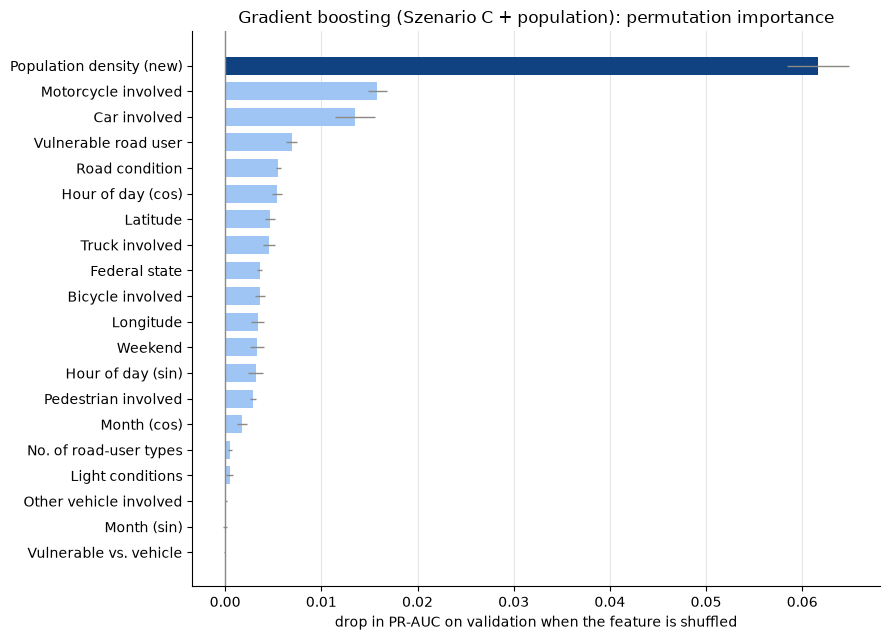

In [9]:
import matplotlib.pyplot as plt

FEATURE_LABELS_C = {
    "log_pop_density": "Population density (new)", "motorcycle": "Motorcycle involved",
    "car": "Car involved", "vulnerable": "Vulnerable road user", "road_condition": "Road condition",
    "hour_cos": "Hour of day (cos)", "hour_sin": "Hour of day (sin)", "latitude": "Latitude",
    "longitude": "Longitude", "truck": "Truck involved", "state_name": "Federal state",
    "bicycle": "Bicycle involved", "is_weekend": "Weekend", "pedestrian": "Pedestrian involved",
    "month_cos": "Month (cos)", "month_sin": "Month (sin)", "n_participant_types": "No. of road-user types",
    "light": "Light conditions", "other_vehicle": "Other vehicle involved",
    "vulnerable_vs_vehicle": "Vulnerable vs. vehicle",
}

importance_plot_c = importance_gb_c.sort_values("PR-AUC drop")
is_new = importance_plot_c["feature"] == "log_pop_density"

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(importance_plot_c["feature"].map(FEATURE_LABELS_C), importance_plot_c["PR-AUC drop"],
        xerr=importance_plot_c["std"], color=np.where(is_new, "#104281", "#9ec5f4"),
        error_kw={"ecolor": "#8a8983", "elinewidth": 1}, height=0.7)
ax.axvline(0, color="#8a8983", lw=1)
ax.set(xlabel="drop in PR-AUC on validation when the feature is shuffled",
       title="Gradient boosting (Szenario C + population): permutation importance")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.grid(axis="x", color="#e6e5e1")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

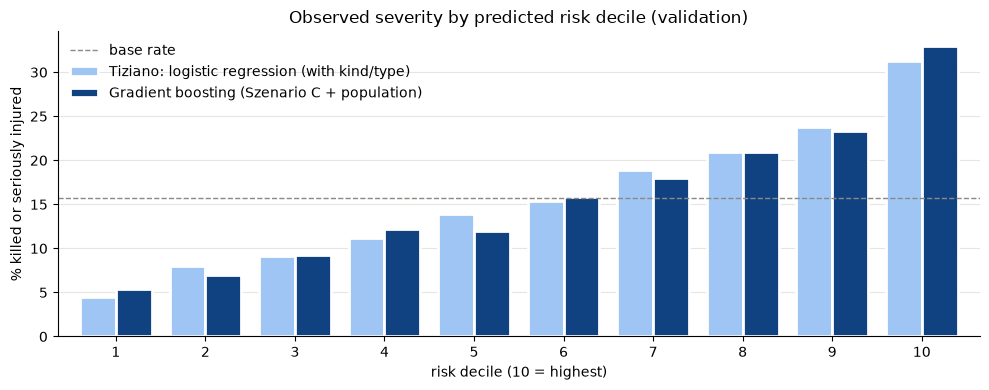

risk decile (10 = highest),1,2,3,4,5,6,7,8,9,10
Tiziano: logistic regression (with kind/type),4.4,8.0,9.1,11.2,13.9,15.4,18.8,20.9,23.8,31.3
Gradient boosting (Szenario C + population),5.4,7.0,9.3,12.1,12.0,15.8,18.0,20.9,23.4,33.0


In [10]:
# Predicted risk on val: Tiziano's logistic regression vs. gradient boosting (Szenario C + population)
features_tiziano_c = sum(FEATURE_SETS["Tiziano (with kind/type)"].values(), [])
lift_pred_c = {
    "Tiziano: logistic regression (with kind/type)":
        logreg_models_c["Tiziano (with kind/type)"].predict_proba(acc_val_df[features_tiziano_c])[:, 1],
    "Gradient boosting (Szenario C + population)":
        tree_models_c["Gradient boosting"].predict_proba(acc_val_df[features_trees_c])[:, 1],
}

# Sort val accidents by predicted risk, cut into 10 equal groups, share severe per group
lift_c = pd.DataFrame({
    name: pd.Series(y_val_c.to_numpy()).groupby(
        pd.qcut(pd.Series(p).rank(method="first"), 10, labels=range(1, 11))).mean() * 100
    for name, p in lift_pred_c.items()
})
lift_c.index.name = "risk decile (10 = highest)"

fig, ax = plt.subplots(figsize=(10, 4))
lift_c.plot.bar(ax=ax, color=["#9ec5f4", "#104281"], width=0.8, edgecolor="white", linewidth=2)
ax.axhline(y_val_c.mean() * 100, color="#8a8983", ls="--", lw=1, label="base rate")
ax.set(ylabel="% killed or seriously injured", title="Observed severity by predicted risk decile (validation)")
ax.tick_params(axis="x", rotation=0)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.grid(axis="y", color="#e6e5e1")
ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

lift_c.round(1).T

In [11]:
import time
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Tuning only on train (5-fold CV), val stays for the final comparison
gb_search_c = RandomizedSearchCV(
    make_pipeline(make_preprocessor(fs_trees_c), HistGradientBoostingClassifier(
        max_iter=1000, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, random_state=42)),
    param_distributions={
        "histgradientboostingclassifier__learning_rate": loguniform(0.02, 0.2),
        "histgradientboostingclassifier__max_leaf_nodes": randint(15, 64),
        "histgradientboostingclassifier__min_samples_leaf": randint(50, 500),
        "histgradientboostingclassifier__l2_regularization": loguniform(1e-3, 10),
    },
    n_iter=20, scoring="average_precision",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1, random_state=42,
)

start = time.time()
gb_search_c.fit(acc_train_df[features_trees_c], y_train_c)
print(f"Search done in {time.time() - start:.0f} s")
print(f"Best CV PR-AUC (train): {gb_search_c.best_score_:.4f}")
print({k.split("__")[1]: round(v, 4) for k, v in gb_search_c.best_params_.items()})

# Tuned model on val, same metrics as before
gb_tuned_c = gb_search_c.best_estimator_
p_train_tuned = gb_tuned_c.predict_proba(acc_train_df[features_trees_c])[:, 1]
p_val_tuned = gb_tuned_c.predict_proba(acc_val_df[features_trees_c])[:, 1]
threshold_tuned = best_f1_threshold(y_train_c, p_train_tuned)
flags_tuned = p_val_tuned >= threshold_tuned

tuned_row_c = pd.Series({
    "Brier skill": 1 - brier_score_loss(y_val_c, p_val_tuned) / brier_constant_c,
    "ROC-AUC": roc_auc_score(y_val_c, p_val_tuned),
    "PR-AUC": average_precision_score(y_val_c, p_val_tuned),
    "threshold": threshold_tuned,
    "% flagged": flags_tuned.mean() * 100,
    "precision": precision_score(y_val_c, flags_tuned),
    "recall": recall_score(y_val_c, flags_tuned),
    "F1": f1_score(y_val_c, flags_tuned),
}, name="Szenario C + population: Gradient boosting (tuned)")

comparison_tuned_c = pd.concat([comparison_c, tuned_row_c.to_frame().T])
comparison_tuned_c.round(4)

Search done in 91 s
Best CV PR-AUC (train): 0.2675
{'l2_regularization': np.float64(0.6797), 'learning_rate': np.float64(0.021), 'max_leaf_nodes': 16, 'min_samples_leaf': 393}


,Brier skill,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Tiziano (with kind/type),0.0463,0.6666,0.2629,0.1629,39.3230,0.2384,0.5974,0.3408
Szenario C,0.0271,0.6290,0.2325,0.1504,44.6975,0.2142,0.6100,0.3171
Szenario C + population,0.0436,0.6604,0.2600,0.1540,41.5300,0.2288,0.6054,0.3320
Szenario C + population: Random forest,0.0496,0.6683,0.2716,0.1882,29.7030,0.2550,0.4826,0.3337
Szenario C + population: Gradient boosting,0.0504,0.6697,0.2713,0.1745,34.6645,0.2492,0.5505,0.3431
Szenario C + population: Gradient boosting (tuned),0.0510,0.6709,0.2715,0.1726,35.7766,0.2472,0.5636,0.3437


In [12]:
from sklearn.metrics import confusion_matrix, classification_report

# FINAL: evaluate once on the test set (untouched until now)
y_test_c = acc_test_df[TARGET]
brier_constant_test_c = brier_score_loss(y_test_c, np.full(len(y_test_c), y_train_c.mean()))

final_models_c = {
    "Tiziano (with kind/type)": (logreg_models_c["Tiziano (with kind/type)"], features_tiziano_c),
    "Final: Gradient boosting tuned (Szenario C + population)": (gb_tuned_c, features_trees_c),
}

final_rows_c = []
for name, (model, features) in final_models_c.items():
    p_train = model.predict_proba(acc_train_df[features])[:, 1]
    p_test = model.predict_proba(acc_test_df[features])[:, 1]
    threshold = best_f1_threshold(y_train_c, p_train)   # same rule as before: chosen on train
    flags = p_test >= threshold
    final_rows_c.append(pd.Series({
        "Brier skill": 1 - brier_score_loss(y_test_c, p_test) / brier_constant_test_c,
        "ROC-AUC": roc_auc_score(y_test_c, p_test),
        "PR-AUC": average_precision_score(y_test_c, p_test),
        "threshold": threshold,
        "% flagged": flags.mean() * 100,
        "precision": precision_score(y_test_c, flags),
        "recall": recall_score(y_test_c, flags),
        "F1": f1_score(y_test_c, flags),
    }, name=name))

final_results_c = pd.DataFrame(final_rows_c)
print(f"TEST set: {len(y_test_c):,} accidents, base rate {y_test_c.mean():.3f}\n")
print(final_results_c.round(4).to_string())

# Confusion matrix + report for the final model
p_test_final = gb_tuned_c.predict_proba(acc_test_df[features_trees_c])[:, 1]
flags_test_final = (p_test_final >= threshold_tuned).astype(int)
print("\nFinal model – confusion matrix (rows = truth, columns = prediction):")
print(pd.DataFrame(confusion_matrix(y_test_c, flags_test_final),
                   index=["true: not severe", "true: severe"],
                   columns=["pred: not severe", "pred: severe"]))
print("\n" + classification_report(y_test_c, flags_test_final, target_names=["not severe", "severe"], digits=3))

TEST set: 40,927 accidents, base rate 0.157

                                                          Brier skill  ROC-AUC  PR-AUC  threshold  % flagged  precision  recall      F1
Tiziano (with kind/type)                                       0.0442   0.6618  0.2607     0.1629    38.8277     0.2372  0.5865  0.3378
Final: Gradient boosting tuned (Szenario C + population)       0.0481   0.6644  0.2679     0.1726    35.5438     0.2435  0.5510  0.3377

Final model – confusion matrix (rows = truth, columns = prediction):
                  pred: not severe  pred: severe
true: not severe             23494         11005
true: severe                  2886          3542

              precision    recall  f1-score   support

  not severe      0.891     0.681     0.772     34499
      severe      0.243     0.551     0.338      6428

    accuracy                          0.661     40927
   macro avg      0.567     0.616     0.555     40927
weighted avg      0.789     0.661     0.704     40927



# Can we predict which road accidents will be severe – before they happen?

## The idea in one paragraph
Every accident with injured people in Germany is recorded by the police. We used all such accidents from **2025** to train a computer model that estimates, for any accident situation, **how likely it is that someone is killed or seriously injured**. The model only uses information that is known **before** an accident happens – *where* (city or countryside, which state), *when* (hour, month, weekend), *under which conditions* (daylight or darkness, dry or wet road) and *who is typically on the road* (cars, bicycles, motorcycles, trucks, pedestrians). This kind of model can help with **prevention**: showing road planners and safety campaigns which situations are the most dangerous.

---

## 1. The data

**Source:** the *Unfallatlas* (accident atlas) of the German statistical offices, year 2025. We added the **population and area of the municipality** where each accident happened.

- **One row = one accident** in which at least one person was injured.
- **272,812 accidents**, **41 columns** (pieces of information per accident).

**What we want to predict – the "target":** the column `severe`
- `severe = 1` → someone was **killed or seriously injured**
- `severe = 0` → people were only **slightly injured**
- **15.7 %** of all accidents are severe. This number is called the **base rate**: if you guessed blindly, you would expect about 16 severe accidents out of 100.

**Starting point – the baseline approach:** the first models built on this data (linear and logistic regression, and simple rules) reached a score of about 0.667 (explained in section 6). They use the **kind of accident** (e.g. "collision with oncoming traffic") – but that is only known **after** the accident. Our goal: get a similarly good model **without** that information, so it can be used for prevention. We call this **"Szenario C"**.

---

## 2. Step 1 – Choosing which information the model may use

A model can only be as honest as the information you give it. We went through all 41 columns and decided for each one:

| ❌ Not used | Columns | Why |
|---|---|---|
| Contains the answer | `severity`, `killed` | They tell you directly whether the accident was severe. Using them would be like giving a student the answer sheet – a perfect score, but nothing learned. This mistake is called **leakage**. |
| Only known after the accident | `accident_kind`, `accident_type` | Useless for prevention (Szenario C). |
| No useful information | accident ID, municipality code, year (always 2025), date, quality-check columns | Identifiers or constants. |
| Repeats other columns | e.g. `state` (same as `state_name`), map coordinates in a second format, raw population and area | Already covered by other columns. |
| Too many different values | region (44), district (513), municipality (9,446) | Too many small groups for the model to learn from reliably. |

**✅ Used (18 pieces of information):**

| Group | What it means |
|---|---|
| **Where** | federal state, longitude and latitude (position on the map), **population density** = people per km² in the municipality (high = city, low = countryside) – *new in our dataset* |
| **When** | hour of the day, month, weekend yes/no |
| **Conditions** | light (daylight, twilight, darkness), road surface (dry, wet, icy) |
| **Who is on the road** | was a car / bicycle / pedestrian / motorcycle / truck / other vehicle involved (yes/no), number of different road-user types |
| **For tree models only** | "vulnerable road user involved" (bicycle, pedestrian or motorcycle) and "vulnerable road user vs. vehicle" |

A small check in the code confirms that every one of the 41 columns was decided exactly once.

---

## 3. Step 2 – Splitting the data into three parts

A model must be tested on accidents it has **never seen** – otherwise we only know how well it memorises. So the accidents are divided into three groups:

| Part | Accidents | What it is used for | School analogy |
|---|---|---|---|
| **Train** (70 %) | 190,970 | The model **learns** from these | studying the textbook |
| **Validation** (15 %) | 40,915 | We **compare models** and make choices | practice exams |
| **Test** (15 %) | 40,927 | **Final grade – used only once**, at the very end | the real exam |

- Each part has the same share of severe accidents (15.7 %). This is called a **stratified** split.
- We used **exactly the same split as the baseline approach**, so the results can be compared directly.

---

## 4. Step 3 – Preparing the data for the model

Models only understand numbers, so some information has to be translated first:

| What we did | Why | Example |
|---|---|---|
| **Words → 0/1 columns** ("one-hot encoding") | A model can't calculate with "darkness" | `light = darkness` becomes a column "darkness" = 1 |
| **Hour and month as a circle** (sine/cosine) | 23:00 and 00:00 are neighbours, but the numbers 23 and 0 look far apart | the clock becomes a circle |
| **Weekend yes/no** | weekends have different traffic | Saturday, Sunday = 1 |
| **Population density on a log scale** | values range from 2 to 4,844 people/km²; the log squeezes the extreme cities together | 10 → 2.4, 1,000 → 6.9 |
| **Scaling** (putting all numbers on the same "ruler") | some models give big numbers more weight just because they are big | latitude and density become comparable |

**Important rule:** all of these translations are learned **only from the training data** and then applied to validation and test – just as a real future accident wouldn't be known in advance. The code does this automatically with a **pipeline** (a fixed chain of steps).

We prepared three versions of the information, so we can see what each piece adds:

| Version | What's in it |
|---|---|
| Baseline approach | everything above **plus** accident kind/type (after-the-accident information) |
| Szenario C | everything above **without** accident kind/type and **without** population density |
| Szenario C + population | Szenario C **plus** the new population density |

---

## 5. Step 4 – The models

A model looks at the training accidents and learns which combinations of information often lead to severe accidents. For a new accident it then gives a **probability**, e.g. "28 % chance this is severe".

| Model | How it works, in simple words |
|---|---|
| **Logistic regression** | Gives every piece of information a weight ("motorcycle: +, city: −"), adds them up and turns the sum into a probability. Simple and easy to explain, but it can't combine information (e.g. "motorcycle **and** countryside **and** night"). |
| **Random forest** | Builds 300 different **decision trees** (chains of yes/no questions like "countryside? → motorcycle? → night?"). Each tree sees a slightly different sample of the data, and the trees then **vote**. Individual mistakes cancel each other out. |
| **Gradient boosting** | Also builds many small decision trees, but **one after another**: each new tree focuses on the mistakes the previous ones made. Often the strongest model for tables like ours. |

---

## 6. Step 5 – How we judge a model

### From probability to a yes/no decision
The model gives a probability. To make a decision ("flag as dangerous: yes/no") we need a cut-off value, the **threshold**. The usual 50 % would flag almost nothing, because severe accidents are rare. We used the threshold that gives the best balance between catching severe accidents and raising false alarms (around **17 %**), chosen on the training data.

### The scores

| Score | Question it answers | How to read it |
|---|---|---|
| **ROC-AUC** | If I pick one severe and one mild accident at random – how often does the model give the severe one the higher risk? | 0.5 = coin flip, 1.0 = perfect |
| **PR-AUC** | How well does the model find the rare severe accidents? | guessing = 0.157 (the base rate), 1.0 = perfect |
| **Brier skill** | Are the probabilities better than always saying "15.7 %"? | 0 = no better, 1 = perfect |
| **Recall** | Of all severe accidents, how many did the model catch? | higher = fewer missed |
| **Precision** | When the model raises an alarm, how often is it really severe? | higher = fewer false alarms |
| **F1** | One number balancing recall and precision | higher = better balance |

**Why not simply "% correct" (accuracy)?** A lazy model that always says "not severe" is already 84 % correct – and catches **zero** severe accidents. With a rare outcome, accuracy is misleading.

---

## 7. Results – comparing the models (validation data)

| # | Model | Information used | ROC-AUC | PR-AUC | F1 |
|---|---|---|---|---|---|
| 1 | Logistic regression | Baseline approach (with accident kind/type) | 0.667 | 0.263 | 0.341 |
| 2 | Logistic regression | Szenario C | 0.629 | 0.233 | 0.317 |
| 3 | Logistic regression | Szenario C + population | 0.660 | 0.260 | 0.332 |
| 4 | Random forest | Szenario C + population | 0.668 | 0.272 | 0.334 |
| 5 | **Gradient boosting** | **Szenario C + population** | **0.670** | **0.271** | **0.343** |

**What this tells us, step by step:**
1. **Row 1:** The baseline result (0.667) comes out the same on our new dataset → the data is consistent.
2. **Row 2:** Taking away the after-the-accident information makes the model worse (0.667 → 0.629). That's expected.
3. **Row 3:** Adding **population density** brings back about **85 %** of what was lost (0.660). One new piece of information almost replaces the accident kind.
4. **Rows 4–5:** Tree models can combine information ("motorcycle **and** countryside") and reach the level of the baseline model – **using only information known before the accident**. Gradient boosting is our best model.

---

## 8. Which information matters most?

To find out, we took the best model and **shuffled one column at a time** (so it becomes meaningless) and measured how much worse the model got. The bigger the drop, the more the model depends on that information.

| Rank | Information | Drop in PR-AUC |
|---|---|---|
| 1 | **Population density (city vs. countryside)** | **0.062** |
| 2 | Motorcycle involved | 0.016 |
| 3 | Car involved | 0.014 |
| 4 | Vulnerable road user involved | 0.007 |
| 5 | Road condition | 0.006 |
| … | hour of day, position, truck, state, bicycle, weekend, pedestrian, month | small |
| last | light, other vehicle, number of road-user types, vulnerable vs. vehicle | ≈ 0 |

- **City vs. countryside is by far the most important factor** – about 4× more than any other. In the most rural fifth of municipalities **24 %** of accidents are severe, in the most urban fifth only **10.7 %** (higher speeds on country roads).
- **Motorcycles** come second: riders have no protection.
- **Light conditions** seem unimportant, but that's because the **hour of day** already tells the model whether it's dark.
- This shows what the model **relies on**, not what **causes** accidents.

---

## 9. Done after this notebook version (to be added)

**Risk groups ("lift"):** we sorted the validation accidents by predicted risk and split them into 10 equal groups. In the **10 % highest-risk situations, 1 in 3 accidents (33 %) is severe** – twice the average (15.7 %). Baseline model: 31 %.

**Fine-tuning ("hyperparameter tuning"):** we let the computer try 20 different settings of the gradient boosting (e.g. how big each tree may be), each checked 5 times on different parts of the training data ("cross-validation"). Result: 0.670 → 0.671 – **almost no gain**. The model has reached what this information can tell us.

**Final exam (test data, used once):**

| Model | ROC-AUC | PR-AUC | F1 | Recall | Accidents flagged |
|---|---|---|---|---|---|
| Baseline model (with accident kind/type) | 0.662 | 0.261 | 0.338 | 59 % | 38.8 % |
| **Our final model** (gradient boosting, before-accident information only) | **0.664** | **0.268** | **0.338** | 55 % | **35.5 %** |

What the final model does on the 40,927 test accidents:

| | Model says: not severe | Model says: severe |
|---|---|---|
| **Really not severe** (34,499) | 23,494 ✔ | 11,005 false alarms |
| **Really severe** (6,428) | 2,886 missed | **3,542 caught ✔** |

- It **catches 55 %** of severe accidents while flagging about a third of all accidents.
- When it raises an alarm, the accident is severe **24 %** of the time – about **1.5× more often** than by chance (15.7 %).
- The scores on the test data are almost the same as on validation → the model works on **new** accidents, it didn't just memorise.

---

## 10. Conclusion
- A model that uses **only information known before an accident** is **as good as** a model that uses information from **after** the accident.
- The key is the **new information about city vs. countryside**: rural roads are where accidents most often end badly.
- For prevention, the model can point to the **most dangerous situations** – e.g. motorcycles on rural roads – where campaigns and road changes would help most.

**Limits:** the scores are moderate (0.66 out of 1). Whether an accident is severe also depends on things that are **not in the data**: speed, speed limit, type of road, helmet or seatbelt use, age of the people involved.

## 11. Next steps (new notebook, following the course)
1. Start with a **single decision tree**, then random forest, then gradient boosting – to show step by step why each is better.
2. Leave out scaling for tree models (trees don't need it).
3. Fine-tune the random forest as well.
4. Compare models with their **spread** (± range), to see whether a difference is real or luck.
5. Tell the model to pay extra attention to the rare severe accidents (`class_weight="balanced"`).
6. Choose the threshold for the real goal, e.g. "catch at least 70 % of severe accidents".
7. Give the final score a **confidence range**, e.g. "0.664 (between 0.657 and 0.671)".